In [1]:
# Loading the cleaned retail sales dataset from the processed data folder for customer-level RFM analysis

import pandas as pd
import numpy as np

df = pd.read_csv("../data/processed/cleaned_data.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (100000, 28)


,Customer ID,Customer Name,Last Name,Date of Birth,Sales,Year,Outlet Type,City Type,Category of Goods,Region,...,Postal Code,Product ID,Sub-Category,Product Name,Quantity,Discount,Profit,Month,Quarter,Year-Month
0,CUST000001,Curtis,Krause,1973-11-29,3344.69,2020,Large,Tier 1,Fast Food,East,...,700001,PROD000001,Burgers,Burgers - 718,3,0.09,448.24,4,2,2020-04
1,CUST000002,Jeremy,Foster,1987-08-30,37094.41,2021,Medium,Tier 2,Fast Food,East,...,160001,PROD000002,Pizzas,Pizzas - 519,5,0.39,3134.34,1,1,2021-01
2,CUST000003,Ariel,Mccann,1980-12-15,35501.08,2020,Large,Village,Electric Appliances,South,...,380001,PROD000003,Fans,Fans - 395,6,0.07,8324.21,8,3,2020-08
3,CUST000004,Colleen,Maynard,1989-05-23,8969.33,2021,Medium,Village,Dairy Products,East,...,700001,PROD000004,Milk,Milk - 798,4,0.18,1962.66,10,4,2021-10
4,CUST000005,Gina,Holden,1957-12-31,35530.44,2019,Small,Village,Sessional Fruits & Vegetables,West,...,110001,PROD000005,Tomatoes,Tomatoes - 442,4,0.27,2843.93,1,1,2019-01


In [2]:
# Checking the number of transactions recorded for each customer to determine whether meaningful RFM frequency values can be calculated

customer_transaction_counts = (
    df.groupby("Customer ID")
    .size()
    .reset_index(name="Transaction_Count")
)

print("Unique Customers:", customer_transaction_counts["Customer ID"].nunique())
print("Minimum Transactions per Customer:", customer_transaction_counts["Transaction_Count"].min())
print("Maximum Transactions per Customer:", customer_transaction_counts["Transaction_Count"].max())

print("\nTransaction Count Distribution:")
display(
    customer_transaction_counts["Transaction_Count"]
    .value_counts()
    .sort_index()
)

Unique Customers: 100000
Minimum Transactions per Customer: 1
Maximum Transactions per Customer: 1

Transaction Count Distribution:


Transaction_Count
1    100000
Name: count, dtype: int64

In [3]:
# Defining the customer analysis reference date as one day after the latest recorded order date

df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

reference_date = df["Order Date"].max() + pd.Timedelta(days=1)

print("Latest Order Date:", df["Order Date"].max())
print("RFM Reference Date:", reference_date)

Latest Order Date: 2023-12-31 00:00:00
RFM Reference Date: 2024-01-01 00:00:00


In [4]:
# Calculating customer-level Recency, Frequency, and Monetary values from the transaction data

rfm = (
    df.groupby("Customer ID")
    .agg(
        Recency=("Order Date", lambda x: (reference_date - x.max()).days),
        Frequency=("Order ID", "nunique"),
        Monetary=("Sales", "sum")
    )
    .reset_index()
)

print("RFM Dataset Shape:", rfm.shape)

display(rfm.head())

RFM Dataset Shape: (100000, 4)


,Customer ID,Recency,Frequency,Monetary
0,CUST000001,1358,1,3344.69
1,CUST000002,1088,1,37094.41
2,CUST000003,1238,1,35501.08
3,CUST000004,813,1,8969.33
4,CUST000005,1805,1,35530.44


In [5]:
'''
100,000 customers
Recency: calculated in days
Frequency: 1 for every customer
Monetary: total Sales per customer
'''

'\n100,000 customers\nRecency: calculated in days\nFrequency: 1 for every customer\nMonetary: total Sales per customer\n'

In [6]:
# Checking the statistical distribution of Recency, Frequency, and Monetary values before customer segmentation

print("RFM Statistical Summary:")
display(
    rfm[
        ["Recency", "Frequency", "Monetary"]
    ].describe()
)

print("\nFrequency Value Counts:")
display(
    rfm["Frequency"]
    .value_counts()
    .sort_index()
)

RFM Statistical Summary:


,Recency,Frequency,Monetary
count,100000.000000,100000.0,100000.000000
mean,913.401580,1.0,25084.410142
std,527.441668,0.0,14403.187686
min,1.000000,1.0,100.570000
25%,456.000000,1.0,12618.030000
50%,914.000000,1.0,25134.695000
75%,1371.000000,1.0,37575.850000
max,1826.000000,1.0,49999.890000



Frequency Value Counts:


Frequency
1    100000
Name: count, dtype: int64

In [7]:
'''
The statistics confirm:

Recency ranges from 1 to 1,826 days.
Median Recency is 914 days.
Monetary ranges from ₹100.57 to ₹49,999.89.
Frequency is exactly 1 for all 100,000 customers.
'''

'\nThe statistics confirm:\n\nRecency ranges from 1 to 1,826 days.\nMedian Recency is 914 days.\nMonetary ranges from ₹100.57 to ₹49,999.89.\nFrequency is exactly 1 for all 100,000 customers.\n'

In [8]:
# Creating five-level Recency and Monetary scores to prepare customers for RFM-based segmentation

rfm["Recency_Score"] = pd.qcut(
    rfm["Recency"],
    q=5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["Monetary_Score"] = pd.qcut(
    rfm["Monetary"],
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

display(
    rfm[
        [
            "Customer ID",
            "Recency",
            "Recency_Score",
            "Frequency",
            "Monetary",
            "Monetary_Score"
        ]
    ].head(10)
)

,Customer ID,Recency,Recency_Score,Frequency,Monetary,Monetary_Score
0,CUST000001,1358,2,1,3344.69,1
1,CUST000002,1088,3,1,37094.41,4
2,CUST000003,1238,2,1,35501.08,4
3,CUST000004,813,3,1,8969.33,1
4,CUST000005,1805,1,1,35530.44,4
5,CUST000006,1475,1,1,420.76,1
6,CUST000007,1106,2,1,31588.07,4
7,CUST000008,780,3,1,4419.87,1
8,CUST000009,1028,3,1,41494.09,5
9,CUST000010,657,4,1,39717.64,4


In [9]:
# Combining the Recency and Monetary scores into an overall RFM score for each customer

rfm["RFM_Score"] = (
    rfm["Recency_Score"] +
    rfm["Monetary_Score"]
)

display(
    rfm[
        [
            "Customer ID",
            "Recency",
            "Recency_Score",
            "Frequency",
            "Monetary",
            "Monetary_Score",
            "RFM_Score"
        ]
    ].head(10)
)

print("\nRFM Score Distribution:")
display(
    rfm["RFM_Score"]
    .value_counts()
    .sort_index()
)

,Customer ID,Recency,Recency_Score,Frequency,Monetary,Monetary_Score,RFM_Score
0,CUST000001,1358,2,1,3344.69,1,3
1,CUST000002,1088,3,1,37094.41,4,7
2,CUST000003,1238,2,1,35501.08,4,6
3,CUST000004,813,3,1,8969.33,1,4
4,CUST000005,1805,1,1,35530.44,4,5
5,CUST000006,1475,1,1,420.76,1,2
6,CUST000007,1106,2,1,31588.07,4,6
7,CUST000008,780,3,1,4419.87,1,4
8,CUST000009,1028,3,1,41494.09,5,8
9,CUST000010,657,4,1,39717.64,4,8



RFM Score Distribution:


RFM_Score
2      4002
3      8029
4     11959
5     15967
6     19918
7     16144
8     11966
9      8044
10     3971
Name: count, dtype: int64

In [10]:
#The RFM score ranges from 2 to 10, with higher scores indicating a combination of more recent purchases and higher monetary value.

In [11]:
# Scaling Recency and Monetary values so both features contribute appropriately to K-Means customer clustering

from sklearn.preprocessing import StandardScaler

rfm_features = rfm[
    ["Recency", "Monetary"]
].copy()

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_features)

rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=["Recency_Scaled", "Monetary_Scaled"]
)

print("Scaled RFM Shape:", rfm_scaled.shape)

display(rfm_scaled.head())

Scaled RFM Shape: (100000, 2)


,Recency_Scaled,Monetary_Scaled
0,0.842938,-1.509376
1,0.331031,0.833847
2,0.615424,0.723223
3,-0.190357,-1.118861
4,1.690429,0.725262


In [12]:
'''
Recency_Scaled → standardized Recency
Monetary_Scaled → standardized Monetary
Shape: 100,000 customers × 2 clustering features
'''

'\nRecency_Scaled → standardized Recency\nMonetary_Scaled → standardized Monetary\nShape: 100,000 customers × 2 clustering features\n'

,Number_of_Clusters,Inertia
0,2,125013.379013
1,3,79362.718204
2,4,50147.286843
3,5,42420.598173
4,6,35876.815568
5,7,30323.070299
6,8,25641.778095


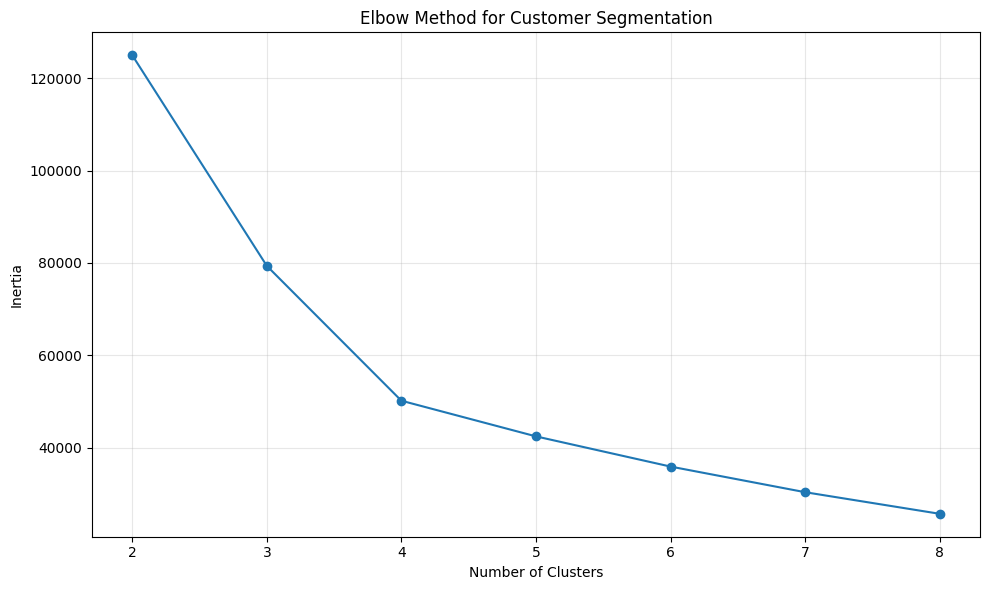

In [13]:
# Calculating K-Means inertia for different cluster counts to identify a suitable number of customer segments

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia_values = []

cluster_range = range(2, 9)

for k in cluster_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(rfm_scaled)
    inertia_values.append(kmeans.inertia_)

elbow_data = pd.DataFrame({
    "Number_of_Clusters": list(cluster_range),
    "Inertia": inertia_values
})

display(elbow_data)

plt.figure(figsize=(10, 6))

plt.plot(
    elbow_data["Number_of_Clusters"],
    elbow_data["Inertia"],
    marker="o"
)

plt.title("Elbow Method for Customer Segmentation")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(list(cluster_range))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [14]:
'''
The Elbow curve shows a substantial reduction in inertia from 2 → 3 → 4 clusters, 
followed by a much slower reduction after 4. So 4 clusters is a reasonable choice for this dataset.
'''

'\nThe Elbow curve shows a substantial reduction in inertia from 2 → 3 → 4 clusters, \nfollowed by a much slower reduction after 4. So 4 clusters is a reasonable choice for this dataset.\n'

In [15]:
# Applying K-Means clustering with four customer segments using the scaled Recency and Monetary features

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

print("Number of Customers in Each Cluster:")
display(
    rfm["Cluster"]
    .value_counts()
    .sort_index()
)

print("\nCluster Centers:")
display(
    pd.DataFrame(
        scaler.inverse_transform(kmeans.cluster_centers_),
        columns=["Recency", "Monetary"]
    )
)

Number of Customers in Each Cluster:


Cluster
0    24850
1    24695
2    25300
3    25155
Name: count, dtype: int64


Cluster Centers:


,Recency,Monetary
0,453.875680,37577.698354
1,1373.993623,12442.630684
2,1367.352709,37450.784482
3,460.429618,12733.577901


In [16]:
# Profiling each customer cluster using average Recency, Monetary value, RFM score, and customer count

cluster_profile = (
    rfm.groupby("Cluster")
    .agg(
        Customer_Count=("Customer ID", "count"),
        Average_Recency=("Recency", "mean"),
        Average_Monetary=("Monetary", "mean"),
        Average_RFM_Score=("RFM_Score", "mean")
    )
    .reset_index()
)

cluster_profile["Customer_Percentage"] = (
    cluster_profile["Customer_Count"]
    / len(rfm)
    * 100
)

display(
    cluster_profile.style.format({
        "Average_Recency": "{:.2f}",
        "Average_Monetary": "₹{:,.2f}",
        "Average_RFM_Score": "{:.2f}",
        "Customer_Percentage": "{:.2f}%"
    })
)

,Cluster,Customer_Count,Average_Recency,Average_Monetary,Average_RFM_Score,Customer_Percentage
0,0,24850,454.24,"₹37,558.91",8.41,24.85%
1,1,24695,1372.61,"₹12,452.60",3.58,24.70%
2,2,25300,1367.80,"₹37,460.03",6.00,25.30%
3,3,25155,459.16,"₹12,715.02",6.00,25.16%


In [17]:
# Assigning business-friendly segment names to the four K-Means customer clusters based on Recency and Monetary behavior

segment_names = {
    0: "Recent High-Value",
    1: "Inactive Low-Value",
    2: "Inactive High-Value",
    3: "Recent Low-Value"
}

rfm["Customer_Segment"] = rfm["Cluster"].map(segment_names)

print("Customer Segment Distribution:")

segment_distribution = (
    rfm["Customer_Segment"]
    .value_counts()
    .rename_axis("Customer_Segment")
    .reset_index(name="Customer_Count")
)

segment_distribution["Percentage"] = (
    segment_distribution["Customer_Count"]
    / len(rfm)
    * 100
)

display(
    segment_distribution.style.format({
        "Percentage": "{:.2f}%"
    })
)

Customer Segment Distribution:


,Customer_Segment,Customer_Count,Percentage
0,Inactive High-Value,25300,25.30%
1,Recent Low-Value,25155,25.16%
2,Recent High-Value,24850,24.85%
3,Inactive Low-Value,24695,24.70%


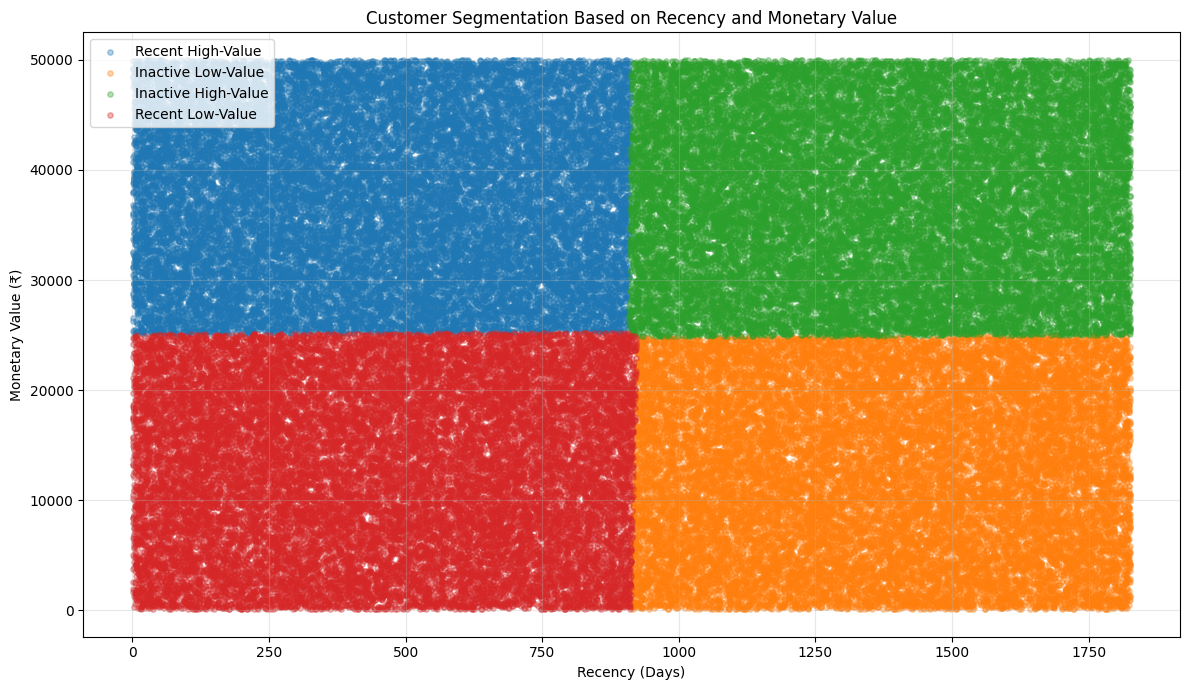

In [18]:
# Visualizing the customer segments based on Recency and Monetary values to inspect the separation between clusters

plt.figure(figsize=(12, 7))

for cluster, segment_name in segment_names.items():
    cluster_data = rfm[rfm["Cluster"] == cluster]
    
    plt.scatter(
        cluster_data["Recency"],
        cluster_data["Monetary"],
        label=segment_name,
        alpha=0.35,
        s=15
    )

plt.title("Customer Segmentation Based on Recency and Monetary Value")
plt.xlabel("Recency (Days)")
plt.ylabel("Monetary Value (₹)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
# Creating the final customer segment profile with customer count, recency, monetary value, and RFM score summaries

segment_profile = (
    rfm.groupby("Customer_Segment")
    .agg(
        Customer_Count=("Customer ID", "count"),
        Average_Recency=("Recency", "mean"),
        Average_Monetary=("Monetary", "mean"),
        Average_RFM_Score=("RFM_Score", "mean"),
        Minimum_Monetary=("Monetary", "min"),
        Maximum_Monetary=("Monetary", "max")
    )
    .reset_index()
)

segment_profile["Customer_Percentage"] = (
    segment_profile["Customer_Count"]
    / len(rfm)
    * 100
)

display(
    segment_profile.style.format({
        "Average_Recency": "{:.2f}",
        "Average_Monetary": "₹{:,.2f}",
        "Average_RFM_Score": "{:.2f}",
        "Minimum_Monetary": "₹{:,.2f}",
        "Maximum_Monetary": "₹{:,.2f}",
        "Customer_Percentage": "{:.2f}%"
    })
)

,Customer_Segment,Customer_Count,Average_Recency,Average_Monetary,Average_RFM_Score,Minimum_Monetary,Maximum_Monetary,Customer_Percentage
0,Inactive High-Value,25300,1367.80,"₹37,460.03",6.00,"₹24,875.88","₹49,995.82",25.30%
1,Inactive Low-Value,24695,1372.61,"₹12,452.60",3.58,₹100.57,"₹25,018.82",24.70%
2,Recent High-Value,24850,454.24,"₹37,558.91",8.41,"₹25,073.84","₹49,999.89",24.85%
3,Recent Low-Value,25155,459.16,"₹12,715.02",6.00,₹100.75,"₹25,231.68",25.16%


In [20]:
'''
One useful observation is that the four segments are almost evenly distributed at about 25% each, 
which is consistent with the structure produced by the two-feature K-Means clustering.
'''

'\nOne useful observation is that the four segments are almost evenly distributed at about 25% each, \nwhich is consistent with the structure produced by the two-feature K-Means clustering.\n'

In [21]:
# Creating a concise customer segment summary table for use in the dashboard and project report

segment_summary = segment_profile[
    [
        "Customer_Segment",
        "Customer_Count",
        "Customer_Percentage",
        "Average_Recency",
        "Average_Monetary",
        "Average_RFM_Score"
    ]
].copy()

segment_summary = segment_summary.sort_values(
    "Average_RFM_Score",
    ascending=False
).reset_index(drop=True)

display(
    segment_summary.style.format({
        "Customer_Percentage": "{:.2f}%",
        "Average_Recency": "{:.2f}",
        "Average_Monetary": "₹{:,.2f}",
        "Average_RFM_Score": "{:.2f}"
    })
)

,Customer_Segment,Customer_Count,Customer_Percentage,Average_Recency,Average_Monetary,Average_RFM_Score
0,Recent High-Value,24850,24.85%,454.24,"₹37,558.91",8.41
1,Recent Low-Value,25155,25.16%,459.16,"₹12,715.02",6.00
2,Inactive High-Value,25300,25.30%,1367.80,"₹37,460.03",6.00
3,Inactive Low-Value,24695,24.70%,1372.61,"₹12,452.60",3.58


In [22]:
'''
Recent High-Value: 24.85%, average spend ₹37,558.91
Recent Low-Value: 25.16%, average spend ₹12,715.02
Inactive High-Value: 25.30%, average spend ₹37,460.03
Inactive Low-Value: 24.70%, average spend ₹12,452.60
'''

'\nRecent High-Value: 24.85%, average spend ₹37,558.91\nRecent Low-Value: 25.16%, average spend ₹12,715.02\nInactive High-Value: 25.30%, average spend ₹37,460.03\nInactive Low-Value: 24.70%, average spend ₹12,452.60\n'

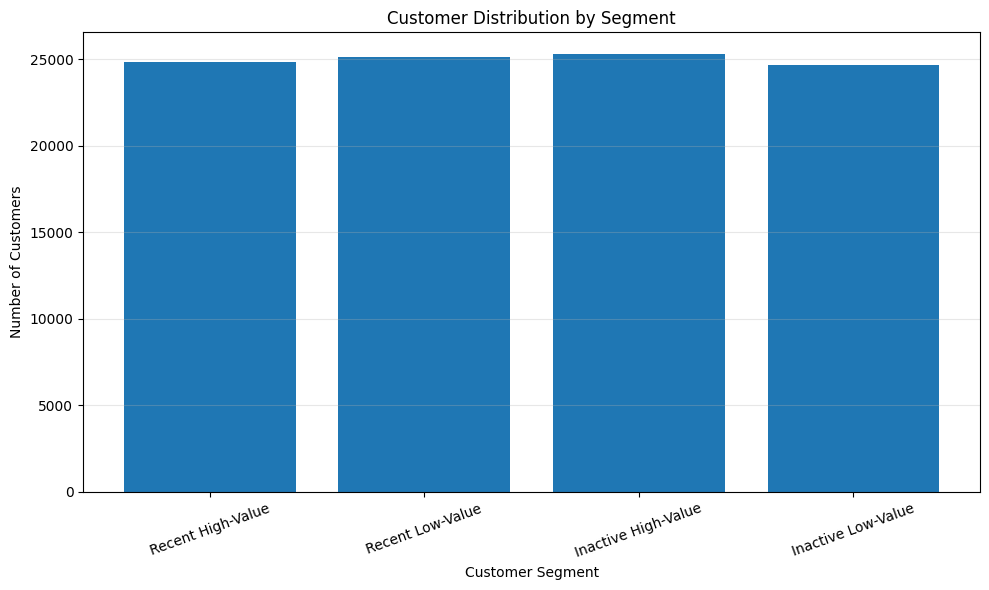

In [23]:
# Visualizing the distribution of customers across the four business-oriented customer segments

plt.figure(figsize=(10, 6))

plt.bar(
    segment_summary["Customer_Segment"],
    segment_summary["Customer_Count"]
)

plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

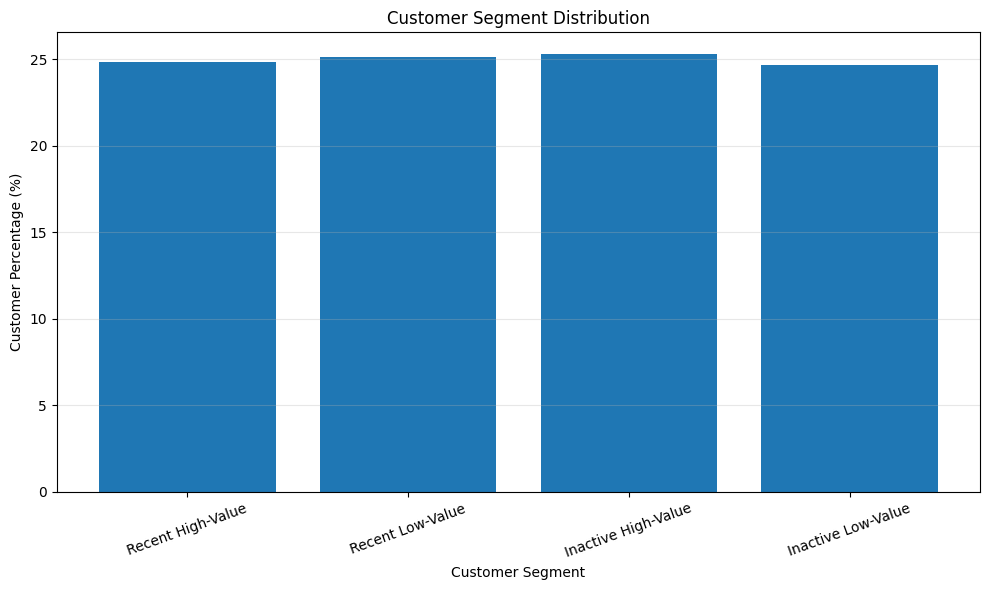

In [24]:
# Visualizing the percentage distribution of customers across the four customer segments

plt.figure(figsize=(10, 6))

plt.bar(
    segment_summary["Customer_Segment"],
    segment_summary["Customer_Percentage"]
)

plt.title("Customer Segment Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Customer Percentage (%)")

plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [25]:
# Saving the customer-level RFM analysis and assigned customer segments for reuse in the dashboard and project report

rfm.to_csv(
    "../data/processed/customer_rfm_segments.csv",
    index=False
)

print("Customer RFM segmentation saved successfully.")
print("File: ../data/processed/customer_rfm_segments.csv")
print("Shape:", rfm.shape)

Customer RFM segmentation saved successfully.
File: ../data/processed/customer_rfm_segments.csv
Shape: (100000, 9)


In [26]:
# Saving the customer segment summary table for use in the dashboard and project report

segment_summary.to_csv(
    "../data/processed/customer_segment_summary.csv",
    index=False
)

print("Customer segment summary saved successfully.")
print("File: ../data/processed/customer_segment_summary.csv")
print("Shape:", segment_summary.shape)

Customer segment summary saved successfully.
File: ../data/processed/customer_segment_summary.csv
Shape: (4, 6)


In [27]:
# Saving the trained K-Means clustering model and feature scaler for reproducible customer segmentation

import joblib

joblib.dump(
    kmeans,
    "../models/customer_segmentation_kmeans.pkl"
)

joblib.dump(
    scaler,
    "../models/customer_segmentation_scaler.pkl"
)

print("Customer segmentation model and scaler saved successfully.")
print("Model: ../models/customer_segmentation_kmeans.pkl")
print("Scaler: ../models/customer_segmentation_scaler.pkl")

Customer segmentation model and scaler saved successfully.
Model: ../models/customer_segmentation_kmeans.pkl
Scaler: ../models/customer_segmentation_scaler.pkl


In [28]:
# Validating the final customer segmentation to confirm that every customer has exactly one valid segment assignment

print("Total Customers:", len(rfm))
print("Customers with Missing Segment:", rfm["Customer_Segment"].isna().sum())
print("Unique Customer IDs:", rfm["Customer ID"].nunique())
print("Unique Customer Segments:", rfm["Customer_Segment"].nunique())

print("\nFinal Segment Counts:")
display(
    rfm["Customer_Segment"]
    .value_counts()
    .sort_index()
)

print("\nValidation Status:")

if (
    rfm["Customer_Segment"].isna().sum() == 0
    and rfm["Customer ID"].nunique() == len(rfm)
    and rfm["Customer_Segment"].nunique() == 4
):
    print("Customer segmentation validation completed successfully.")
else:
    print("Please review the customer segmentation results.")

Total Customers: 100000
Customers with Missing Segment: 0
Unique Customer IDs: 100000
Unique Customer Segments: 4

Final Segment Counts:


Customer_Segment
Inactive High-Value    25300
Inactive Low-Value     24695
Recent High-Value      24850
Recent Low-Value       25155
Name: count, dtype: int64


Validation Status:
Customer segmentation validation completed successfully.
